# 모의고사 17회 | 주택가격·다중분류·장바구니 추천 풀이

자료 이해 → 고정 분석 조건 → 문항별 풀이 근거 → 실행 코드 → 실제 결과의 순서로 읽으십시오. 전체를 위에서 아래로 실행합니다. 변수의 산업적 의미는 각 절의 사전을 따르며, 공식 정답이나 실제 현장 성능을 뜻하지 않습니다.

실제 결과를 모은 [해설](해설.md)과 [자료 사전](자료안내.md)을 함께 사용하십시오.

In [1]:
from pathlib import Path
import sys

FOLDER = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
sys.path.insert(0, str(FOLDER.parent / "공통"))
from researched_core import ResearchContext

ctx = ResearchContext(FOLDER)

## 1. 주택가격 설명과 예측

**상황을 이해하기**

관측의 조건과 결과 관계를 설명하고 새 관측의 결과를 예측한다.

**관측 단위와 판단 목적**

한 행은 서로 독립인 관측이다. x1=면적 편차지수, x2=노후도 편차지수, x3=교통 접근 점수, target=가격(천만원). 추론의 조건과 예측 성능을 구분해 보고한다.

**변수 사전**

| 열 | 의미·역할 |
| --- | --- |
| `id` | 독립 관측 식별자; 입력 제외 |
| `x1` | 면적 편차지수 |
| `x2` | 노후도 편차지수 |
| `x3` | 교통 접근 점수 |
| `group` | 관측 집단 범주 A/B; 처치 아님 |
| `target` | 가격(천만원) |

**고정 분석 조건**

x1=면적 편차지수, x2=노후도 편차지수, x3=교통 접근 점수, target=가격(천만원). 240행. x1에 결측이 있다. id를 제외하고 중앙값 대치 후 수치형은 학습 평균/표준편차(ddof0)로 표준화하고 집단은 one-hot(drop first) 처리한 뒤 OLS를 적합한다. x1,x2,x3의 단순/전체모형 비교는 같은 학습 행이다. random_state=20281017로 학습70%/평가30%를 나누고 학습3-fold shuffled CV를 사용한다. 다항식 차수2, RF60나무 깊이3/5는 사전 후보다.

### 1-1

**문제 (10점)**

관측 단위·입력·반응·누출 위험과 결측을 정리하고 지정한 학습/평가 원행을 기록하시오. 학습 입력의 분포와 변수 관계를 ax 두 개에 제시하시오.

**풀이 근거와 읽는 순서**

식별자·사후 반응은 제외하고 대치는 학습 자료에서만 추정한다.

평가 설계를 먼저 고정한다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

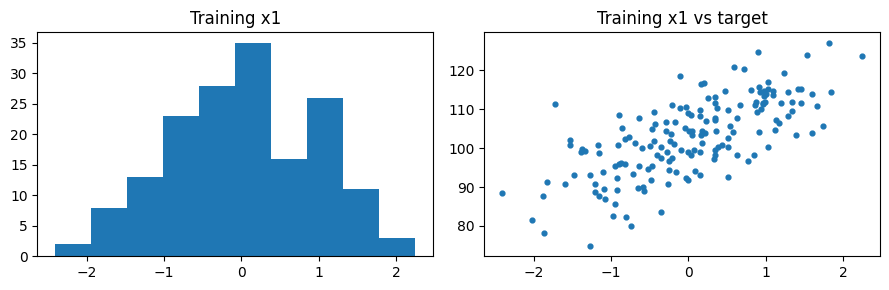

n: 240


,metric,value
0,x1,3
1,x2,0
2,x3,0
3,group,0


conclusion: 학습 168행·봉인 평가 72행. 실제값으로 만든 파생변수는 사용하지 않는다.


In [2]:
ctx.run("1-1", "reg_1")

### 1-2

**문제 (10점)**

학습 자료에 지정 OLS를 적합하고 계수 t 검정·전체 F 검정·R²·수정 R²·AIC·BIC를 보고하시오. 단순모형과 전체모형의 비교에서 같은 행과 반응을 유지하시오.

**풀이 근거와 읽는 순서**

t는 조건부 계수, F는 전체 설명항의 검정이다.

학습 R²와 예측 성능을 구분하며 같은 반응·행에서만 정보량을 비교한다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [3]:
ctx.run("1-2", "reg_2")

coefficient_scale: 수치형은 학습 표준편차1단위, 범주는 B−A. 교호작용은 표준화 좌표의 곱.


,term,coefficient,standard_error,t_statistic,p_value,ci_lower,ci_upper,reject_h0
0,Intercept,100.491406,0.390345,257.442722,1.151099e-214,99.720622,101.262191,True
1,numeric__x1,7.333263,0.256991,28.535090,2.767299e-65,6.825802,7.840724,True
2,numeric__x2,-5.119799,0.253625,-20.186514,3.356920e-46,-5.620613,-4.618986,True
3,numeric__x3,2.579606,0.253305,10.183805,3.692727e-19,2.079424,3.079787,True
4,category__group_B,4.134051,0.519934,7.951115,2.913755e-13,3.107378,5.160725,True


,metric,value
0,r2,0.892694
1,adjusted_r2,0.890061
2,r2_kind,centered
3,f_statistic,339.006741
4,f_p_value,0.0
5,f_kind,classical overall F
6,df_model,4.0
7,df_resid,163.0
8,n_samples,168
9,aic,880.959071


,metric,value
0,r2,0.493974
1,adjusted_r2,0.490926
2,r2_kind,centered
3,f_statistic,162.046344
4,f_p_value,0.0
5,f_kind,classical overall F
6,df_model,1.0
7,df_resid,166.0
8,n_samples,168
9,aic,1135.511607


,test,statistic,p_value,reject_h0,df_num,df_den
0,nested-model F,201.889078,1.160356e-54,True,3.0,163.0


conclusion: 학습 R² 0.8927는 봉인 평가 성능이 아니다. 계수 t·F는 사전 OLS 사양과 추론 가정에 조건부다.


### 1-3

**문제 (10점)**

RESET·잔차 정규성·Breusch-Pagan·VIF·Cook을 계산하고 Q-Q·잔차/적합값을 subplots로 제시하시오. 명시하지 않은 관측 제거를 수행하지 말고 진단별 한계를 설명하시오.

**풀이 근거와 읽는 순서**

정규성은 y가 아니라 잔차를 대상으로 한다.

VIF는 변수의 공선성, Cook은 관측 영향력이다.

비기각을 가정 증명으로 쓰지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

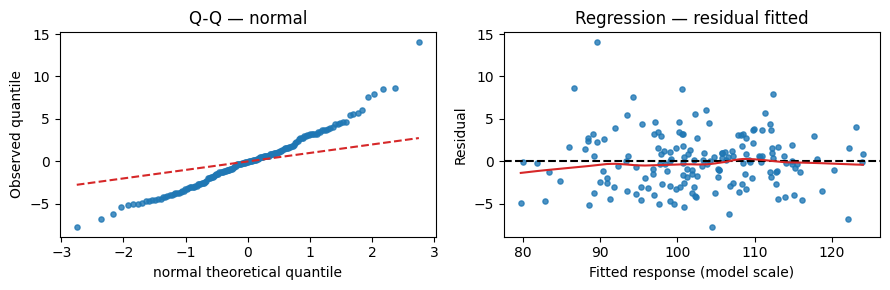

,test,statistic,p_value,reject_h0,df_num,df_den
0,jarque_bera,29.375544,4.180052e-07,True,None,None


,test,statistic,p_value,reject_h0,df_num,df_den
0,RESET F,0.201001,0.818116,False,2.0,161.0


,test,statistic,p_value,reject_h0,df_num,df_den
0,breusch_pagan LM,6.983480,0.136764,False,None,None
1,breusch_pagan F,1.767377,0.137874,False,None,None


,feature,vif,tolerance,flag
0,numeric__x1,1.030371,0.970524,False
1,numeric__x2,1.003554,0.996458,False
2,numeric__x3,1.001023,0.998978,False
3,category__group_B,1.032853,0.968192,False


,position,row_label,residual,studentized_internal,studentized_external,leverage,cooks_distance,dffits,outlier_p,adjusted_outlier_p,cook_flag,leverage_flag,studentized_flag,outlier_reject,original_position
41,41,41,14.103358,4.376458,4.644408,0.035620,0.141490,0.892598,0.000007,0.001179,True,False,True,True,107
14,14,14,-7.770898,-2.439959,-2.478140,0.058055,0.073385,-0.615221,0.014232,1.000000,True,False,False,False,16
137,137,137,8.654761,2.702070,2.756205,0.047280,0.072466,0.613997,0.006518,1.000000,True,False,False,False,2
45,45,45,-4.911222,-1.552217,-1.559013,0.070343,0.036461,-0.428843,0.120945,1.000000,True,True,False,False,85
52,52,52,-6.801198,-2.109565,-2.132395,0.034764,0.032056,-0.404685,0.034481,1.000000,True,False,False,False,10


removed_rows: 0
conclusion: 본 풀이에서는 영향 관측을 삭제하지 않는다. 진단은 사양 점검이며 비기각을 가정의 증명으로 읽지 않는다.


In [4]:
ctx.run("1-3", "reg_3")

### 1-4

**문제 (10점)**

동일 학습 CV에서 기준 선형모형·다항식·랜덤포레스트를 RMSE로 비교해 하나를 선택하시오. 봉인한 같은 평가 행에서 원단위 RMSE·MAE·R²와 관측-예측 그림을 제시하고 기준 대비 차이를 해석하시오.

**풀이 근거와 읽는 순서**

전처리를 CV 안에서 적합한다.

설명용 OLS 진단과 선택한 예측모형의 적용 조건을 구분하고 최종평가로 다시 고르지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

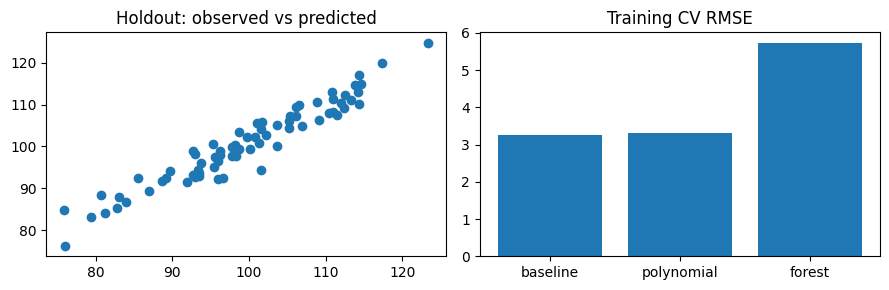

,candidate,cv_rmse,parameters
0,baseline,3.265117,{}
1,polynomial,3.311138,{}
2,forest,5.725151,{'model__max_depth': 5}


selected: baseline


,metric,value
0,rmse,3.172279
1,mae,2.515122
2,r2,0.909259


,metric,value
0,rmse,3.172279
1,mae,2.515122
2,r2,0.909259


delta_r2: 0.0
baseline_predictions: [102.32196057324256, 110.99832614376092, 85.17251894150553, 100.22524784527555, 94.38298769356426, 102.82620461678532, 98.96206477237507, 76.1654926440219, 86.81563631819026, 102.18576738799014, 114.89297340982915, 94.07637586594123, 107.95620645994013, 93.18102965846191, 104.93909265956013, 108.19313843366618, 94.43071669789896, 105.95844263153683, 114.66960346960678, 92.35870730353874, 84.7543441449532, 99.29293800460822, 100.70895573921739, 110.12595791427272, 105.69203161956194, 103.45001057725261, 119.95531624450538, 92.40543880228584, 93.75380704602911, 107.28612898557974, 89.36602273630284, 111.35522660381984, 91.44434724235136, 124.85215651899941, 99.33577710702902, 91.70871623489789, 97.79210016626259, 105.05766682056543, 113.13088138963063, 98.99857877098661, 92.81225014040794, 100.66842227401678, 109.21369089790235, 110.5873755346413, 117.12395947793522, 87.931500883356, 109.92639235083189, 110.37853403477993, 96.45802051520826, 104.052843

In [5]:
ctx.run("1-4", "reg_4")

## 2. 서비스 다중분류와 제출

**상황을 이해하기**

고객 등급은 서비스 이용 후 확정되므로 현재 등급을 입력으로 넣으면 누출이다.

**관측 단위와 판단 목적**

한 행은 서로 독립인 가상 이용자다. 별도 제출 파일의 target은 제공하지 않는다. 평가와 제출 예측을 분리하고 분류 확률의 한계를 검토한다.

**변수 사전**

| 열 | 의미·역할 |
| --- | --- |
| `id` | 학습/제출 관측 식별자; 입력 제외 |
| `x1` | 사건 전에 측정한 수치 지표1 |
| `x2` | 사건 전에 측정한 수치 지표2 |
| `x3` | 사건 전에 측정한 수치 지표3 |
| `group` | 사건 전에 알려진 서비스 종류 A/B/C |
| `target` | 학습 자료에만 있는 정수 클래스; 제출 자료에는 없음 |

**고정 분석 조건**

학습360행과 정답 없는 제출24행은 별개다. target은 0=기본,1=일반,2=우수 서비스 등급; 등급은 관측 후 확정된 결과다. id는 입력 제외. random_state=20281017로 층화70/30, 학습3-fold shuffled CV. 수치 중앙값 대치·표준화, group 최빈 대치·one-hot(handle_unknown=ignore)를 CV 안에서 적합한다. 후보는 LR C=0.3/1, RF60나무 깊이3/5, GB40단계 깊이2, LR/RF/GB 동일 가중 soft voting이다. 추가 sampling은 적용하지 않는다.

### 2-1

**문제 (10점)**

사건/클래스 정의·시점·식별자·결측·클래스 비율을 정리하고 층화 학습/평가 분리 원행을 제시하시오. 범주별 목표 분포를 ax에 표시하시오.

**풀이 근거와 읽는 순서**

알 수 없는 범주는 학습된 인코더가 처리하며 평가 자료의 발생률을 인위적으로 바꾸지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

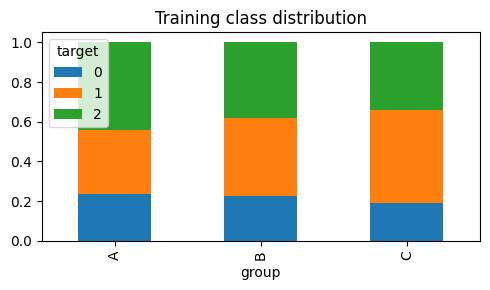

classes: [0, 1, 2]


,metric,value
0,0,79
1,1,141
2,2,140


conclusion: 층화 분리 후 평가 발생률은 유지한다. 클래스 순서와 확률 열 순서를 함께 저장한다.


In [6]:
ctx.run("2-1", "cls_1")

### 2-2

**문제 (10점)**

지정한 여러 분류기와 soft voting을 같은 학습 CV로 비교하시오. 학습 폴드 내부 전처리·지정 sampling·GridSearchCV를 사용하고 macro F1로 선택한 설정과 CV 결과를 기록하시오.

**풀이 근거와 읽는 순서**

sampling은 fit 전에 CV 학습 폴드에만 적용한다.

soft voting은 확률 평균이며 개별 모델보다 좋다는 보장은 없다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [7]:
ctx.run("2-2", "cls_2")

,candidate,cv_macro_f1,parameters
0,logit,0.555092,{'model__C': 0.3}
1,forest,0.502933,{'model__max_depth': 5}
2,boost,0.536678,{}
3,soft_voting,0.535943,{}


selected: logit
sampling: False
conclusion: 학습 CV macro F1로 logit 선택. 확률 평균 앙상블이 항상 개별 후보보다 좋지는 않다.


### 2-3

**문제 (10점)**

선택 후보를 전체 학습 자료에 적합하고 평가 혼동행렬·클래스별 재현율·macro F1·클래스 순서를 제시하시오. 이진 또는 one-vs-rest ROC와 AUC를 ax별로 그리고 확률 보정·임계값 한계를 설명하시오.

**풀이 근거와 읽는 순서**

다중분류 AUC는 클래스별 one-vs-rest를 macro 집계한다.

이진 사건의 점수와 다중 확률 행렬을 혼동하지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

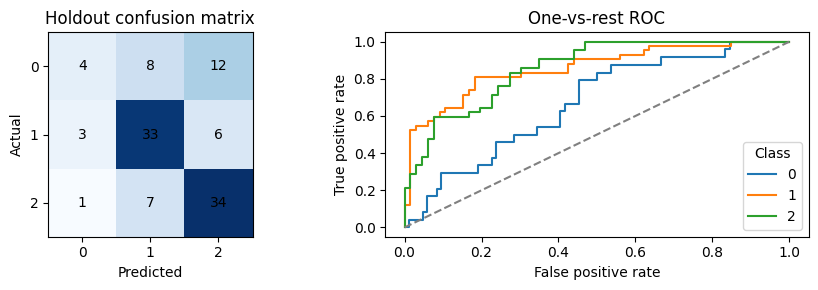

labels: [0, 1, 2]
confusion_matrix: [[4, 8, 12], [3, 33, 6], [1, 7, 34]]
recall_by_class: [0.16666666666666666, 0.7857142857142857, 0.8095238095238095]
macro_f1: 0.5689125295508274
roc_auc: 0.7942370129870131
auc_definition: macro one-vs-rest
conclusion: 보류 macro F1=0.5689, AUC=0.7942. 최저 재현율 클래스 0=0.1667도 함께 검토해야 한다. 높은 AUC는 확률 보정·최적 비용 임계값을 보장하지 않는다.


In [8]:
ctx.run("2-3", "cls_3")

### 2-4

**문제 (10점)**

라벨 없는 별도 제출 자료를 예측해 id·prediction 열의 submission.csv를 저장하시오. 행 순서·식별자·라벨 정의역·중복·누락을 검사하고 평가 점수와 실제 제출 자료의 성능을 구분하시오.

**풀이 근거와 읽는 순서**

제출용 실제 정답이 없으므로 그 성능을 계산하지 않는다.

최종평가로 임계값·후보를 다시 선택하지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [9]:
ctx.run("2-4", "cls_4")

submission_rows: 24
unique_ids: True


,metric,value
0,0,6
1,1,9
2,2,9


,id,prediction
0,361,1
1,362,1
2,363,1
3,364,1
4,365,2


conclusion: 제출 24행을 원 순서로 저장했다. 제출 자료의 정답이 없으므로 실제 제출 정확도는 알 수 없다.


## 3. 장바구니 추천 응용

**상황을 이해하기**

점포가 동시 구매 패턴으로 상품 진열·추천 후보를 만든다.

**관측 단위와 판단 목적**

한 행은 독립 거래 한 건이다. 연관 규칙을 직접 검산하고 관찰 관계의 한계를 설명한다.

**변수 사전**

| 열 | 의미·역할 |
| --- | --- |
| `id` | 거래 식별자 |
| `items` | |로 구분된 품목; 빈 문자열은 빈 거래 |

**고정 분석 조건**

거래100건. items는 | 구분 문자열이며 공백 거래도 하나의 거래다. 추천 대상 장바구니는 [bread]다. 전체 자료의 기술 연관분석이며 별도 미래 성능은 없다.

### 3-1

**문제 (5점)**

거래 식별자와 항목 목록을 분리하고 거래 안 중복 항목을 제거하시오. 빈 거래 포함 지지도 분모와 추천 목적을 설명하시오.

**풀이 근거와 읽는 순서**

관측 단위는 거래 한 건이다.

항목별 행 수가 아니라 거래 비율이 지지도다.

전체는 기술 분석 자료다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [10]:
ctx.run("3-1", "assoc_1")

transactions: 100
empty_transactions: 12
conclusion: 빈 거래를 포함한100건이 지지도 분모다. 거래 내 반복 품목은 한 번만 센다.


### 3-2

**문제 (5점)**

최소 지지도0.15·신뢰도0.5·lift1·최대 길이3으로 Apriori를 실행하고 빈발 항목집합·규칙 표를 제시하시오.

**풀이 근거와 읽는 순서**

임계값은 사전 고정한다.

사후 유리한 규칙을 만들기 위해 분모나 임계값을 바꾸지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [11]:
ctx.run("3-2", "assoc_2")

,items,count,support,length
0,[bread],61,0.61,1
1,[fruit],40,0.40,1
2,[milk],62,0.62,1
3,[tea],36,0.36,1
4,"[bread, fruit]",22,0.22,2
5,"[bread, milk]",53,0.53,2
6,"[bread, tea]",20,0.20,2
7,"[fruit, milk]",25,0.25,2
8,"[fruit, tea]",18,0.18,2
9,"[milk, tea]",20,0.20,2


,antecedents,consequents,support,confidence,lift,leverage,conviction
0,[bread],[milk],0.53,0.868852,1.401375,0.1518,2.897500
1,[milk],[bread],0.53,0.854839,1.401375,0.1518,2.686667
2,[fruit],[milk],0.25,0.625000,1.008065,0.0020,1.013333
3,[tea],[fruit],0.18,0.500000,1.250000,0.0360,1.200000
4,"[bread, fruit]",[milk],0.19,0.863636,1.392962,0.0536,2.786667
5,"[fruit, milk]",[bread],0.19,0.760000,1.245902,0.0375,1.625000
6,"[bread, tea]",[milk],0.16,0.800000,1.290323,0.0360,1.900000
7,"[milk, tea]",[bread],0.16,0.800000,1.311475,0.0380,1.950000


rule_count: 8
conclusion: 임계값을 사전 고정한 기술 연관 규칙이다. 출력 규칙 개수는 성과나 매출 효과가 아니다.


### 3-3

**문제 (5점)**

출력 규칙 하나를 원 거래에서 직접 세어 지지도·신뢰도·lift를 검산하시오. 빈 규칙일 때는 없음으로 보고하고 구매의 인과라고 해석하지 마시오.

**풀이 근거와 읽는 순서**

support=P(A∩B), confidence=P(B|A), lift=confidence/P(B)다.

동시 구매와 인과는 다르다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [12]:
ctx.run("3-3", "assoc_3")

rule_exists: True
antecedents: ['bread']
consequents: ['milk']
n: 100
count_a: 61
count_b: 62
count_ab: 53
support: 0.53
confidence: 0.8688524590163934
lift: 1.4013749338974086
reported_support: 0.53
reported_confidence: 0.8688524590163935
reported_lift: 1.4013749338974089
conclusion: 동시 구매와 조건부 비율을 원 거래에서 검산했다. 높은 lift를 구매 유발의 인과로 읽지 않는다.


### 3-4

**문제 (5점)**

관심 장바구니에 적용 가능한 미구매 추천을 만들고 규칙이 없을 때의 동작과 인기 편향·새 고객·운영 검증 한계를 설명하시오.

**풀이 근거와 읽는 순서**

후건에서 이미 구매한 항목을 제외한다.

오프라인 lift는 실제 추가 매출이나 온라인 전환율이 아니다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [13]:
ctx.run("3-4", "assoc_4")

basket: ['bread']


,item,confidence,lift
0,milk,0.868852,1.401375


conclusion: 이미 구매한bread는 제외했다. 적용 규칙이 없으면 추천을 비우고, 추가 매출은 별도 운영 실험으로 확인해야 한다.
